## Étape 3 : JEPA, le world model à partir d’images


Objectif

Jusqu'ici l'agent recevait les coordonnées de la balles. C'est un gros racourci. Dans la vraie vie, un homme qui marche, un robot qui éffectue une tâche ou une voiture qui roule d'un point 1 à un autre B ne recoivent pas explicitement des coordonnées de tous les points de l'environnement. Ces entités reçoivent des images et apprennent à prédire un futur proche dans lequel plusieurs entités sont négligeables et très peu sont à cours terme évolutives.

On veut donc un agent qui :

-voit la balle uniquement à travers des images

-apprend seul une représentation utile et encodée de ces images, le latent ;

-prédit l’évolution du monde dans cet espace latent

-planifie dans cet espace pour atteindre un objectif donné lui aussi sous forme d’image.

À aucun moment l’agent ne connaît les coordonnées de la balle. C’est l’architecture en miniature de l'idée de Yann LeCun.

### Ce qui change par rapport à l’étape 2

| Critère | Étape 2 | Étape 3 |
| :--- | :--- | :--- |
| **Observation** | Positions | Images |
| **Encodeur** | Fixé à la main | Appris (un petit CNN) |
| **Prédiction** | Dans l’espace des positions | Dans l’espace latent |
| **Loss** | MSE sur $\Delta p$ | Prédiction latente + anti-collapse |
| **Objectif à atteindre** | Coordonnées de la cible | Image de la cible |

**Ce qui ne change pas :** Le simulateur, les actions, le *random shooting*, le principe MPC.

L’architecture

Les observations. Des images de 32×32 pixels, avec la balle dessinée comme une petite tache floue. Une tache floue plutôt qu’un disque net, car elle donne un signal plus lisse, plus facile à apprendre.

L’encodeur. Une seule image ne montre pas la vitesse de la balle, exactement comme une seule position à l’étape 1. L’encodeur reçoit donc les 2 dernières images empilées, et en déduit un latent :

$$s(t) = \mathrm{Enc}_\theta\big(x(t-1), x(t)\big)$$

Le prédicteur. Un MLP, comme avant, mais qui travaille sur les latents :

$$\hat{s}(t+1) = \mathrm{Pred}_\phi\big(s(t), a(t)\big)$$

L’énergie. L’écart entre le latent prédit et le latent réellement encodé à l’instant suivant :

$$E = \big\| \hat{s}(t+1) - \mathrm{Enc}\big(x(t), x(t+1)\big) \big\|^2$$

C’est là que la notion d’énergie devient vraiment centrale : le modèle juge la compatibilité entre le présent et le futur dans son propre espace de représentation.

**L’énergie.** L’écart entre le latent prédit et le latent réellement encodé à l’instant suivant :

$$E = \big\| \hat{s}(t+1) - \mathrm{Enc}\big(x(t), x(t+1)\big) \big\|^2$$

Le modèle juge la compatibilité entre le présent et le futur dans son propre espace de représentation.
Ayant déjà travaillé sur un Energie Based Model, il y a un ennemi redoutable qui ce dressera presque naturellement sur notre chemin.
#### L'ennemi redoutable : le *collapse* (éffondrement)

Si on minimise seulement l’énergie, il existe une solution triviale : l’encodeur renvoie toujours le même vecteur. Le prédicteur n’a qu’à le recopier, et l’énergie vaut zéro… sans que rien n’ait été appris.

**Deux familles de solutions :**
* **VICReg :** on ajoute à la *loss* deux termes qui obligent les latents à varier d’une image à l’autre, et leurs dimensions à porter des informations différentes.
* **Encodeur cible à moyenne mobile (EMA) :** le latent de l’image suivante est calculé par une copie de l’encodeur, mise à jour lentement et non entraînée directement (approche de **BYOL** et **I-JEPA**).

Je propose ( et je dispose ) VICReg. C'est une méthode récentes, supervisée par LeCun et ses termes sont explicites et mesurables : si le latent s’effondre, on pourrait le voit immédiatement dans les courbes.

#### L’entraînement

Les données sont les mêmes qu’à l’étape 2 : des trajectoires avec des actions aléatoires, mais enregistrées sous forme d’images. La *loss* totale combine :
1. **un terme de prédiction :** l’énergie ci-dessus ;
2. **un terme de variance :** chaque dimension du latent doit varier sur le *batch* ;
3. **un terme de covariance :** les dimensions doivent être décorrélées entre elles.

L’encodeur et le prédicteur sont entraînés ensemble.

#### L’évaluation, en trois niveaux

1. **Le latent contient-il la bonne information ?**
   On entraîne une simple régression linéaire, appelée **sonde linéaire**, qui doit retrouver la position et la vitesse de la balle à partir du latent. La JEPA n’a jamais vu les coordonnées : si la sonde y arrive bien, c’est que l’encodeur a appris seul à les représenter. C’est la vérification la plus importante.
2. **Le prédicteur est-il précis ?**
   On mesure l’erreur de prédiction dans le latent, à un pas puis en *rollout*, et on la convertit en erreur de position grâce à la sonde, pour la comparer à l’étape 2.
3. **Peut-on planifier ?**
   On donne à l’agent l’image de la balle immobile sur la cible. Il l’encode en latent objectif, et son coût devient la distance entre le latent imaginé et ce latent objectif. On compare ensuite :
   * l’agent aléatoire et l’agent oracle, comme à l’étape 2 ;
   * l’agent *world model* de l’étape 2, qui voit directement les positions ;
   * l’agent JEPA, qui ne voit que des images.

#### Les critères de réussite

* **Pas de *collapse* :** la variance des latents reste élevée pendant tout l’entraînement.
* **Représentation fidèle :** la sonde linéaire retrouve la position avec une erreur faible devant la taille de la boîte.
* **Planification efficace :** l’agent JEPA atteint la cible nettement plus souvent que l’agent aléatoire, et s’approche de l’agent de l’étape 2.

#### Les risques identifiés

| Risque | Comment on le détecte |
| :--- | :--- |
| **Collapse du latent** | Variance des latents qui tend vers zéro |
| **Latent sans la position** | Sonde linéaire peu précise |
| **Distance latente peu adaptée à la planification** | L’agent n’atteint pas la cible, alors que la sonde est bonne |

> **Note :** Le troisième risque est le plus subtil : un latent peut contenir toute l’information, sans que la distance entre latents reflète la distance réelle entre positions. C’est un vrai sujet de recherche, et un résultat intéressant à analyser s’il apparaît.

#### Le plan du notebook

| # | Bloc | GPU |
| :---: | :--- | :---: |
| 1 | Rendu des images de la balle | Non |
| 2 | Génération du dataset d’images et d’actions | Non |
| 3 | Encodeur et prédicteur | x |
| 4 | Loss JEPA avec VICReg | x |
| 5 | Entraînement et suivi du *collapse* | Oui (T4) |
| 6 | Sonde linéaire | Oui |
| 7 | Prédiction latente et *rollouts* | Oui |
| 8 | Planification à partir d’une image objectif | Oui |
| 9 | Comparaison des agents et conclusion | Oui |

#### Une extension possible

Une fois la JEPA fonctionnelle, on pourra ajouter des distracteurs visuels : du bruit ou des objets qui bougent au hasard. On comparera alors la JEPA à un modèle qui reconstruit les pixels. C’est l’expérience qui montre l’argument central de **LeCun** : prédire dans un espace latent permet d’ignorer ce qui est imprévisible et inutile pour la tâche.

## 1- Transformer une position en image

#### L’idée

Le simulateur donne toujours des positions. Pour l’étape 3, on les dessine dans une petite image, et c’est uniquement cette image que l’agent verra.

* **Le format :** Une image en niveaux de gris de $32 \times 32$ pixels, avec des valeurs entre $0$ (noir) et $1$ (blanc). C’est petit, donc rapide à entraîner, et suffisant pour localiser la balle.
* **Le rendu (tache gaussienne) :** La balle est une tache floue, une gaussienne, plutôt qu’un disque net :
  $$\text{pixel}(i, j) = \exp\left(-\frac{(u_j - x)^2 + (v_i - y)^2}{2\sigma^2}\right)$$
  où $(u_j, v_i)$ sont les coordonnées du centre du pixel dans la boîte, et $(x, y)$ la position de la balle.
* **Pourquoi une tache floue ?** Avec un disque net, déplacer la balle d’un dixième de pixel ne change presque aucun pixel. Avec une gaussienne, le moindre déplacement modifie légèrement les intensités : le signal varie de façon continue avec la position, ce qui rend l’apprentissage beaucoup plus facile.
* **L’orientation :** Dans une image, la ligne $0$ est en haut, alors que dans notre boîte, $y = 0$ est en bas. On garde la convention « ligne $i$ = coordonnée $y$ », et on affiche les images avec `origin="lower"` pour que le dessin corresponde à la boîte.

In [1]:
# Configuration générale
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# GPU si disponible (nécessaire à partir de l'entraînement, bloc 5)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

# Simulation (identique à l'étape 2)
V_INIT = 0.03
A_MAX = 0.005
V_MAX = 0.05

# Images
IMG_SIZE = 32
BLOB_SIGMA = 1.5 / IMG_SIZE
pixel_centers = (np.arange(IMG_SIZE) + 0.5) / IMG_SIZE

Device : cpu


In [2]:
SEED = 42
# Simulation
N_TRAJ = 500        # nombre de trajectoires
N_STEPS = 200       # positions par trajectoire
A_MAX = 0.005       # amplitude maximale d'une action, par composante
V_MAX = 0.05        # vitesse maximale, par composante
V_INIT = 0.03       # norme de la vitesse initiale
def simulate_controlled_ball(rng, n_steps, v_init, a_max, v_max, box=(0.0, 1.0)):
    """
    Simule une balle pilotée par des poussées aléatoires dans une boîte carrée,
    avec rebonds élastiques sur les murs.

    Paramètres
    ----------
    rng : np.random.Generator
        Générateur aléatoire partagé.
    n_steps : int
        Nombre de positions dans la trajectoire.
    v_init : float
        Norme de la vitesse initiale.
    a_max : float
        Amplitude maximale d'une action, par composante.
    v_max : float
        Vitesse maximale, par composante.
    box : tuple
        Limites (min, max) de la boîte, identiques sur les deux axes.

    Sorties
    -------
    positions : np.ndarray de forme (n_steps, 2)
    actions : np.ndarray de forme (n_steps - 1, 2)
        actions[t-1] est l'action qui fait passer de positions[t-1] à positions[t].
    bounces : np.ndarray de forme (n_steps,), booléens
        bounces[t] vaut True si un rebond a eu lieu entre les pas t-1 et t.
    """
    low, high = box
    margin = 0.1 * (high - low)

    # Tableaux créés à l'avance
    positions = np.zeros((n_steps, 2))
    actions = np.zeros((n_steps - 1, 2))
    bounces = np.zeros(n_steps, dtype=bool)

    # Position et direction de départ aléatoires
    pos = rng.uniform(low + margin, high - margin, size=2)
    angle = rng.uniform(0.0, 2.0 * np.pi)
    velocity = v_init * np.array([np.cos(angle), np.sin(angle)])
    positions[0] = pos

    for t in range(1, n_steps):

        action = rng.uniform(-a_max, a_max, size=2) # Action aléatoire : une petite poussée sur chaque axe

        velocity = velocity + action   # La poussée modifie la vitesse

        speed = np.linalg.norm(velocity)
        if speed > v_max:
            velocity = velocity * (v_max / speed)   # même direction, norme ramenée à v_max   # La vitesse est limitée sur chaque axe

        pos = pos + velocity  # Déplacement en ligne droite

        for d in range(2):    # rebonds, axe par axe (d = 0 pour x, d = 1 pour y)
            if pos[d] < low:
                pos[d] = 2 * low - pos[d]       # réflexion à l'intérieur de la boîte
                velocity[d] *= -1              # inversion de la vitesse sur cet axe
                bounces[t] = True
            elif pos[d] > high:
                pos[d] = 2 * high - pos[d]
                velocity[d] *= -1
                bounces[t] = True

        # 6. Enregistrement
        positions[t] = pos
        actions[t - 1] = action

    return positions, actions, bounces

In [3]:
# l'environnement
V_MAX = 0.05
def env_step(pos, vel, action, v_max=V_MAX, low=0.0, high=1.0):
    """
    Fait avancer une ou plusieurs balles d'un pas (vraie physique).
    pos, vel, action : tableaux de forme (2,) ou (N, 2).
    """
    #  La poussée modifie la vitesse
    vel = vel + action

    # limitation de la norme de la vitesse (même direction, norme plafonnée)
    speed = np.linalg.norm(vel, axis=-1, keepdims=True)
    vel = np.where(speed > v_max, vel * v_max / np.maximum(speed, 1e-12), vel)

    # Déplacement
    pos = pos + vel

    # Rebonds : réflexion de la position et inversion de la vitesse, axe par axe
    below, above = pos < low, pos > high
    pos = np.where(below, 2 * low - pos, pos)
    pos = np.where(above, 2 * high - pos, pos)
    vel = np.where(below | above, -vel, vel)

    return pos, vel

In [4]:
IMG_SIZE = 32              # taille des images (pixels)
BLOB_SIGMA = 1.5 / IMG_SIZE  # largeur de la tache : environ 1,5 pixel, en unités de la boîte

# coordonnées du centre de chaque pixel, dans la boîte [0, 1]
pixel_centers = (np.arange(IMG_SIZE) + 0.5) / IMG_SIZE

In [5]:
def render(positions, sigma=BLOB_SIGMA):
    """
    Dessine la balle sous forme de tache gaussienne.

    positions : tableau de forme (2,) ou (N, 2), coordonnées dans [0, 1].
    Retourne : images de forme (32, 32) ou (N, 32, 32), valeurs dans [0, 1].
              La ligne i correspond à la coordonnée y, la colonne j à la coordonnée x.
    """
    positions = np.atleast_2d(positions)                       # (N, 2)
    x = positions[:, 0][:, None, None]                         # (N, 1, 1)
    y = positions[:, 1][:, None, None]                         # (N, 1, 1)
    u = pixel_centers[None, None, :]                           # (1, 1, 32) : coordonnées x des colonnes
    v = pixel_centers[None, :, None]                           # (1, 32, 1) : coordonnées y des lignes

    images = np.exp(-((u - x) ** 2 + (v - y) ** 2) / (2 * sigma ** 2))   # (N, 32, 32)
    return images.astype(np.float32).squeeze(0) if len(images) == 1 else images.astype(np.float32)

Forme des images : (200, 32, 32) | min 0.0 | max 0.9993032


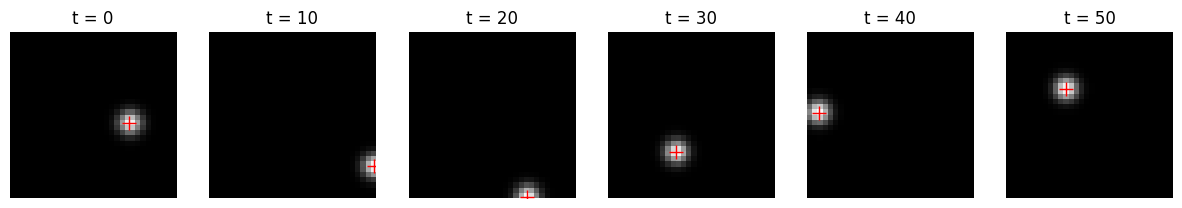

In [6]:
rng = np.random.default_rng(SEED)
positions, actions, bounces = simulate_controlled_ball(rng, N_STEPS, V_INIT, A_MAX, V_MAX)
images = render(positions)
print("Forme des images :", images.shape, "| min", images.min(), "| max", images.max())

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, t in zip(axes, range(0, 60, 10)):
    ax.imshow(images[t], cmap="gray", origin="lower", extent=(0, 1, 0, 1), vmin=0, vmax=1)
    ax.plot(*positions[t], "r+", ms=10)           # vraie position
    ax.set_title(f"t = {t}"); ax.axis("off")
plt.show()

In [7]:
def center_of_mass(images):
    """Estime la position de la balle comme le barycentre des intensités des pixels."""
    images = images[None] if images.ndim == 2 else images
    total = images.sum(axis=(1, 2))
    x = (images.sum(axis=1) * pixel_centers).sum(axis=1) / total   # moyenne sur les colonnes
    y = (images.sum(axis=2) * pixel_centers).sum(axis=1) / total   # moyenne sur les lignes
    return np.stack([x, y], axis=1)

estimated = center_of_mass(images)
error = np.linalg.norm(estimated - positions, axis=1)
print(f"Erreur moyenne du centre de masse : {error.mean():.4f}")
print(f"Erreur maximale                   : {error.max():.4f}")

Erreur moyenne du centre de masse : 0.0050
Erreur maximale                   : 0.0347


## 2- le dataset d’images

observation (t)  =  images x(t-1), x(t)      ← 2 images empilées : position ET vitesse

action           =  a(t)

observation (t+1) = images x(t), x(t+1)

In [8]:
N_TRAJ = 500
N_STEPS = 200

rng = np.random.default_rng(SEED)
all_positions = np.zeros((N_TRAJ, N_STEPS, 2), dtype=np.float32)
all_actions = np.zeros((N_TRAJ, N_STEPS - 1, 2), dtype=np.float32)
all_frames = np.zeros((N_TRAJ, N_STEPS, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

for i in range(N_TRAJ):
    positions, actions, _ = simulate_controlled_ball(rng, N_STEPS, V_INIT, A_MAX, V_MAX)
    all_positions[i] = positions
    all_actions[i] = actions
    all_frames[i] = np.round(render(positions) * 255).astype(np.uint8)   # stockage compact

print(f"Images : {all_frames.shape}, {all_frames.nbytes / 1e6:.0f} Mo")

# Séparation par trajectoire, comme aux étapes 1 et 2
indices = rng.permutation(N_TRAJ)
n_train, n_val = int(0.8 * N_TRAJ), int(0.1 * N_TRAJ)
split_indices = {
    "train": indices[:n_train],
    "val": indices[n_train : n_train + n_val],
    "test": indices[n_train + n_val :],
}

Images : (500, 200, 32, 32), 102 Mo


- 500 trajectoires de taille 200 chacune soit 200 img/traj
- chaque image est de taille 32x32
- all_frames [i, t] est l’image de la trajectoire i à l’instant t : soit une matrice 32x32
- Au total, il y a 500x200 = 100.000 images pour 102 Mo de stockage

In [9]:
from torch.utils.data import Dataset, DataLoader

class TransitionDataset(Dataset):
    """
    Transitions (observation, action, observation suivante) à partir des images.
    Une observation = 2 images successives empilées, de forme (2, 32, 32).
    """

    def __init__(self, frames, actions, traj_ids):
        self.frames = frames
        self.actions = actions
        n_steps = frames.shape[1]
        # Instants valides : il faut x(t-1) avant et x(t+1) après
        self.index = [(i, t) for i in traj_ids for t in range(1, n_steps - 1)]

    def __len__(self):
        return len(self.index)

    def __getitem__(self, k):
        i, t = self.index[k]
        obs = self.frames[i, t - 1 : t + 1].astype(np.float32) / 255.0        # x(t-1), x(t)
        next_obs = self.frames[i, t : t + 2].astype(np.float32) / 255.0       # x(t), x(t+1)
        action = self.actions[i, t] / A_MAX                                   # a(t), entre -1 et 1
        return torch.from_numpy(obs), torch.from_numpy(action), torch.from_numpy(next_obs)

datasets = {name: TransitionDataset(all_frames, all_actions, ids) for name, ids in split_indices.items()}
for name, ds in datasets.items():
    print(f"{name:5s} : {len(ds)} transitions")

train_loader = DataLoader(datasets["train"], batch_size=256, shuffle=True, num_workers=2)

train : 79200 transitions
val   : 9900 transitions
test  : 9900 transitions


Entraînement : 400 trajectoires × 198 transitions = 79 200 ;

Validation et test : 50 trajectoires × 198 transitions = 9 900 chacun.

Formes : torch.Size([2, 32, 32]) torch.Size([2]) torch.Size([2, 32, 32])


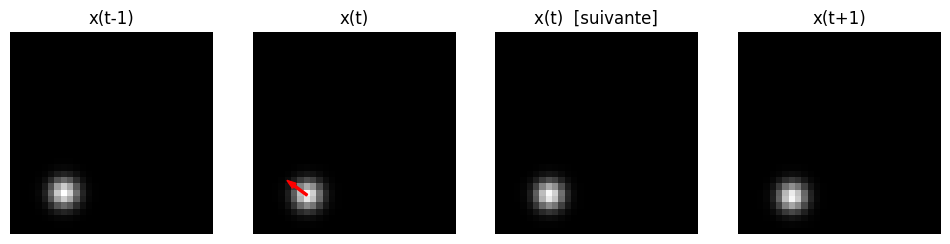

In [10]:
obs, action, next_obs = datasets["train"][100]
print("Formes :", obs.shape, action.shape, next_obs.shape)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
titles = ["x(t-1)", "x(t)", "x(t)  [suivante]", "x(t+1)"]
for ax, img, title in zip(axes, [obs[0], obs[1], next_obs[0], next_obs[1]], titles):
    ax.imshow(img, cmap="gray", origin="lower", extent=(0, 1, 0, 1), vmin=0, vmax=1)
    ax.set_title(title); ax.axis("off")
# L'action, agrandie pour être visible, dessinée depuis la position de la balle à l'instant t
i, t = datasets["train"].index[100]
p = all_positions[i, t]
axes[1].arrow(*p, *(action.numpy() * 0.1), color="red", width=0.01)
plt.show()

Le mouvement est lent donc difficile à voir d'un instant à l'autre. Je propose de visualiser la balle à deux instants consécutif. Celà me sert de vérification à moi même.

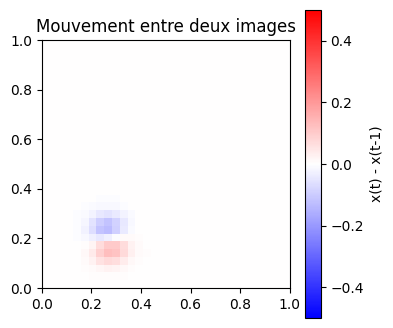

Position en t-1 : [0.26720592 0.20283006]
Position en t   : [0.2689533 0.192313 ]
Déplacement     : [ 0.00174737 -0.01051706]


In [11]:
i, t = datasets["train"].index[100]
diff = obs[1] - obs[0]   # x(t) - x(t-1)

plt.figure(figsize=(4, 4))
plt.imshow(diff, cmap="bwr", origin="lower", extent=(0, 1, 0, 1), vmin=-0.5, vmax=0.5)
plt.colorbar(label="x(t) - x(t-1)")
plt.title("Mouvement entre deux images")
plt.show()

print("Position en t-1 :", all_positions[i, t - 1])
print("Position en t   :", all_positions[i, t])
print("Déplacement     :", all_positions[i, t] - all_positions[i, t - 1])

La balle est passée de la position bleue à la rouge.

## 3- Encodeur et prédicteur

#### L’encodeur : un petit CNN

L’idée est que l'encodeur transforme une observation, c’est-à-dire $2$ images empilées de $32 \times 32$, en un context latent : un vecteur de $32$ nombres.

$$s(t) = \mathrm{Enc}_\theta\big(x(t-1), x(t)\big) \in \mathbb{R}^{32}$$

On passe donc d'un espace de dimension $2 \times 32 \times 32$ à un espace de dim $32$. C'est une projection. ( dans un espace latent ). L'idée est justement de faire en sorte que le modèle ( encoder) apprenne à tirer l'information pertinente et ignorée le reste.

* **Pourquoi un CNN (réseau convolutif) plutôt qu’un MLP ?** Une convolution fait glisser un petit filtre (ici de $3 \times 3$ pixels) sur toute l’image. Chaque filtre apprend à détecter un motif local : un bord de la tache, un sens de déplacement entre les deux images. C’est bien adapté aux images, et ça demande beaucoup moins de paramètres qu’un MLP sur $2\,048$ pixels.
* **Architecture :** On va empiler $3$ convolutions. Chacune divise la taille de l’image par $2$ (avec un *stride* de $2$) et augmente le nombre de canaux :

```text
(2, 32, 32)  ──conv──►  (32, 16, 16)  ──conv──►  (64, 8, 8)  ──conv──►  (128, 4, 4)
                                                                            │ aplatir
                                                                            ▼
                                                    latent (32)  ◄──linear── 2 048

On perd en résolution, mais on gagne en abstraction : à la fin, chaque nombre résume une information sur toute l’image.

* **Pourquoi un latent de 32 nombres ?** L’information utile tient en $4$ nombres (position et vitesse). On laisse de la marge, pour que l’encodeur puisse l’organiser à sa façon. Ce n’est pas un choix critique.

#### Le prédicteur : un MLP

Nous allons ici faire comme dans la partie 2.

Il reçoit le le contexte latent et l’action, et prédit le latent suivant :

$$\hat{s}(t+1) = s(t) + \mathrm{Pred}_\phi\big(s(t),\ a(t)\big)$$

> **Remarque sur le terme $s(t) +$ :** en effet le prédicteur ne prédit pas directement le latent suivant, mais son changement. C’est exactement la même idée que prédire $\Delta p$ plutôt que $p$ aux étapes 1 et 2 : d’un pas à l’autre, l’état change peu, et le réseau se concentre sur ce changement.

In [12]:
LATENT_DIM = 32

class Encoder(nn.Module):
    """Transforme une observation (2 images empilées) en un latent de dimension LATENT_DIM."""

    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, stride=2, padding=1),    # (2, 32, 32)  → (32, 16, 16)
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),   # (32, 16, 16) → (64, 8, 8)
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),  # (64, 8, 8)   → (128, 4, 4)
            nn.ReLU(),
        )
        self.fc = nn.Linear(128 * 4 * 4, latent_dim)                 # 2 048 → latent

    def forward(self, obs):
        h = self.conv(obs)                 # (B, 128, 4, 4)
        h = h.flatten(start_dim=1)         # (B, 2048) : on aplatit tout sauf la dimension du batch
        return self.fc(h)                  # (B, LATENT_DIM)


class Predictor(nn.Module):
    """Prédit le latent suivant à partir du latent actuel et de l'action."""

    def __init__(self, latent_dim=LATENT_DIM, action_dim=2, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim + action_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, latent_dim),
        )

    def forward(self, s, action):
        x = torch.cat([s, action], dim=1)  # (B, LATENT_DIM + 2) : latent et action côte à côte
        return s + self.net(x)             # le réseau prédit le changemnt du latent

Petite vérification.

On fait passer un lot dans les deux réseaux, sans entraînement, juste pour vérifier que les dimensions s’enchaînent :

In [13]:
encoder = Encoder()
predictor = Predictor()

obs, action, next_obs = next(iter(train_loader))
s = encoder(obs)
s_next_pred = predictor(s, action)
s_next = encoder(next_obs)

print("Observation    :", obs.shape)
print("Latent s(t)    :", s.shape)
print("Latent prédit  :", s_next_pred.shape)
print("Latent réel    :", s_next.shape)

n_enc = sum(p.numel() for p in encoder.parameters())
n_pred = sum(p.numel() for p in predictor.parameters())
print(f"Paramètres : encodeur {n_enc:,}, prédicteur {n_pred:,}")

Observation    : torch.Size([256, 2, 32, 32])
Latent s(t)    : torch.Size([256, 32])
Latent prédit  : torch.Size([256, 32])
Latent réel    : torch.Size([256, 32])
Paramètres : encodeur 158,528, prédicteur 82,976


158.528 paramètres  (poids du réseau de neurone)  pour l'encoder et 82,976 pour le prédicteur.

## 4- Loss JEPA avec ViCReg

#### L’idée

D'après l'article, la *loss* a trois termes. Le premier fait apprendre la dynamique, les deux autres empêchent le *collapse* :

$$\mathcal{L} = \lambda_{\text{pred}}\, \mathcal{L}_{\text{pred}} + \lambda_{\text{var}}\, \mathcal{L}_{\text{var}} + \lambda_{\text{cov}}\, \mathcal{L}_{\text{cov}}$$

1. **Le terme de prédiction : l’énergie**
   L’écart entre le latent prédit et le latent réellement encodé à l’instant suivant :
   $$\mathcal{L}_{\text{pred}} = \frac{1}{B} \sum_{b=1}^{B} \frac{1}{D}\, \big\| \hat{s}_b(t+1) - s_b(t+1) \big\|^2$$
   avec $B$ la taille du *batch* et $D = 32$ la dimension du latent. Seul, ce terme mène au *collapse* : un encodeur qui renvoie toujours le même vecteur l’annule.

2. **Le terme de variance : les latents doivent varier**
   Pour chaque dimension $j$ du latent, on calcule son écart-type sur le *batch*, et on pénalise s’il passe sous $1$ :
   $$\mathcal{L}_{\text{var}} = \frac{1}{D} \sum_{j=1}^{D} \max\big(0,\ 1 - \mathrm{std}(s_{\cdot j})\big)$$
   Si l’encodeur renvoyait toujours le même vecteur, tous les écarts-types vaudraient $0$, et ce terme vaudrait $1$ : sa valeur maximale. Il interdit donc le *collapse* complet.

3. **Le terme de covariance : les dimensions doivent porter des informations différentes**
   Le terme de variance ne suffit pas : l’encodeur pourrait faire varier ses $32$ dimensions… en leur faisant toutes porter la même information. On pénalise donc les corrélations entre dimensions, c’est-à-dire les termes hors diagonale de la matrice de covariance $C$ des latents :
   $$\mathcal{L}_{\text{cov}} = \frac{1}{D} \sum_{i \neq j} C_{ij}^2$$

#### Les poids

On reprend ceux de l’article **VICReg** : $\lambda_{\text{pred}} = 25$, $\lambda_{\text{var}} = 25$, $\lambda_{\text{cov}} = 1$. Ce sont de bons points de départ ; on les ajustera si besoin.

> **Remarque :** On applique les termes de variance et de covariance aux latents des deux observations, $s(t)$ et $s(t+1)$, puisque les deux passent par l’encodeur.

In [14]:
LAMBDA_PRED = 25.0
LAMBDA_VAR = 25.0
LAMBDA_COV = 1.0

def variance_loss(s, eps=1e-4):
    """Pénalise les dimensions dont l'écart-type sur le batch est inférieur à 1."""
    std = torch.sqrt(s.var(dim=0) + eps)          # écart-type de chaque dimension : (D,)
    return F.relu(1.0 - std).mean()

def covariance_loss(s):
    """Pénalise les corrélations entre dimensions différentes du latent."""
    B, D = s.shape
    s_centered = s - s.mean(dim=0)
    cov = (s_centered.T @ s_centered) / (B - 1)   # matrice de covariance : (D, D)
    off_diag = cov - torch.diag(torch.diag(cov))  # on retire la diagonale
    return (off_diag ** 2).sum() / D

def jepa_loss(s, s_next_pred, s_next):
    """
    Loss JEPA avec régularisation VICReg.
    s, s_next : latents encodés de l'observation et de l'observation suivante (B, D).
    s_next_pred : latent suivant prédit par le prédicteur (B, D).
    """
    pred = F.mse_loss(s_next_pred, s_next)
    var = variance_loss(s) + variance_loss(s_next)
    cov = covariance_loss(s) + covariance_loss(s_next)

    total = LAMBDA_PRED * pred + LAMBDA_VAR * var + LAMBDA_COV * cov
    return total, {"pred": pred.item(), "var": var.item(), "cov": cov.item()}

In [15]:
total, parts = jepa_loss(s, s_next_pred, s_next)
print(f"Loss totale : {total.item():.3f}")
print(f"Termes      : prédiction {parts['pred']:.4f} | variance {parts['var']:.3f} | covariance {parts['cov']:.4f}")
print(f"Écart-type moyen des latents : {s.std(dim=0).mean().item():.4f}")

Loss totale : 49.533
Termes      : prédiction 0.0018 | variance 1.980 | covariance 0.0000
Écart-type moyen des latents : 0.0021


In [16]:
import os, json
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/jepa_world_model"
FIG_DIR = f"{PROJECT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

MODEL_PATH = f"{PROJECT_DIR}/jepa_step3.pt"
HISTORY_PATH = f"{PROJECT_DIR}/history.json"
print("Dossier du projet :", PROJECT_DIR)

Mounted at /content/drive
Dossier du projet : /content/drive/MyDrive/jepa_world_model


## 5- Entrainement

L’encodeur et le prédicteur sont entraînés ensemble, donc avec un seul optimiseur. À chaque batch :

- on encode l’observation et l’observation suivante : $s(t)$ et $s(t+1)$ ;
- le prédicteur prédit $\hat{s}(t+1)$ à partir de $s(t)$ et de l’action ;
- on calcule la loss JEPA, et on met à jour les deux réseaux.

Pendant l’entraînement, on surveille chaque terme séparément, plus l’écart-type des latents. C’est notre détecteur de collapse : s’il tend vers 0, l’encodeur est en train de s’effondrer.

In [17]:
# preparation
torch.manual_seed(SEED)
encoder = Encoder().to(device)
predictor = Predictor().to(device)

#un seul optimiseur pour les deux réseaux, entraînés ensemble
params = list(encoder.parameters()) + list(predictor.parameters())
optimizer = torch.optim.Adam(params, lr=1e-3)

N_EPOCHS = 30
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)

# même taille de batch qu'à l'entraînement : les termes de variance et de covariance en dépendent
val_loader = DataLoader(
    datasets["val"], batch_size=256, shuffle=True, num_workers=2,
    generator=torch.Generator().manual_seed(SEED),
)

In [18]:
def run_epoch(loader, train):
    """Parcourt un loader. Met à jour les poids si train=True. Renvoie les moyennes des métriques."""
    encoder.train(train)
    predictor.train(train)
    totals = {"loss": 0.0, "pred": 0.0, "var": 0.0, "cov": 0.0, "std": 0.0}
    n = 0

    for obs, action, next_obs in loader:
        obs, action, next_obs = obs.to(device), action.to(device), next_obs.to(device)

        with torch.set_grad_enabled(train):        # gradients uniquement à l'entraînement
            s = encoder(obs)
            s_next = encoder(next_obs)
            s_next_pred = predictor(s, action)
            loss, parts = jepa_loss(s, s_next_pred, s_next)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        b = len(obs)
        totals["loss"] += loss.item() * b
        for key in ("pred", "var", "cov"):
            totals[key] += parts[key] * b
        totals["std"] += s.std(dim=0).mean().item() * b    # écart-type moyen des latents
        n += b

    return {key: value / n for key, value in totals.items()}

In [19]:
# # Training
# history = {"train": [], "val": []}

# for epoch in range(N_EPOCHS):
#     train_metrics = run_epoch(train_loader, train=True)
#     val_metrics = run_epoch(val_loader, train=False)
#     scheduler.step()

#     history["train"].append(train_metrics)
#     history["val"].append(val_metrics)
#     print(f"Époque {epoch:2d} | val : loss {val_metrics['loss']:.3f} | "
#           f"pred {val_metrics['pred']:.4f} | var {val_metrics['var']:.3f} | "
#           f"cov {val_metrics['cov']:.3f} | std latents {val_metrics['std']:.3f}")

# # Sauvegarde : une session Colab peut être coupée à tout moment
# torch.save({"encoder": encoder.state_dict(), "predictor": predictor.state_dict()}, MODEL_PATH)
# print("Modèle sauvegardé :", MODEL_PATH)

In [20]:
# # Sauvegarde du modèle et de l'historique
# torch.save({"encoder": encoder.state_dict(), "predictor": predictor.state_dict()}, MODEL_PATH)

# with open(HISTORY_PATH, "w") as f:
#     json.dump(history, f)

# print("Modèle     :", MODEL_PATH)
# print("Historique :", HISTORY_PATH)

### Reprise sans réentraîner

Les deux cellules ci-dessus sont commentées : **aucun entraînement n'a lieu**.
`encoder` et `predictor` créés dans la cellule de préparation contiennent donc des poids
**aléatoires**. La cellule suivante est obligatoire : elle recharge les poids entraînés
depuis le Drive. Sans elle, tout ce qui suit (sonde, rollouts, planification) évalue un
encodeur non entraîné.


In [21]:
# chargement des poids entraînés depuis le Drive.

checkpoint = torch.load(MODEL_PATH, map_location=device)
encoder = Encoder().to(device)
predictor = Predictor().to(device)
encoder.load_state_dict(checkpoint["encoder"])
predictor.load_state_dict(checkpoint["predictor"])
encoder.eval(); predictor.eval()
print("Poids entraînés rechargés depuis", MODEL_PATH)

# Contrôle : un encodeur entraîné ne devrait pas donner le même latent qu'un encodeur aléatoire.
torch.manual_seed(SEED)
_check_rand = Encoder().to(device)
_obs, _, _ = next(iter(train_loader))
with torch.no_grad():
    _d = (encoder(_obs.to(device)) - _check_rand(_obs.to(device))).abs().mean().item()
print(f"Écart moyen avec un encodeur aléatoire : {_d:.4f}  (doit être nettement > 0)")


Poids entraînés rechargés depuis /content/drive/MyDrive/jepa_world_model/jepa_step3.pt
Écart moyen avec un encodeur aléatoire : 1.0777  (doit être nettement > 0)


In [22]:
with open(HISTORY_PATH) as f:
    history = json.load(f)

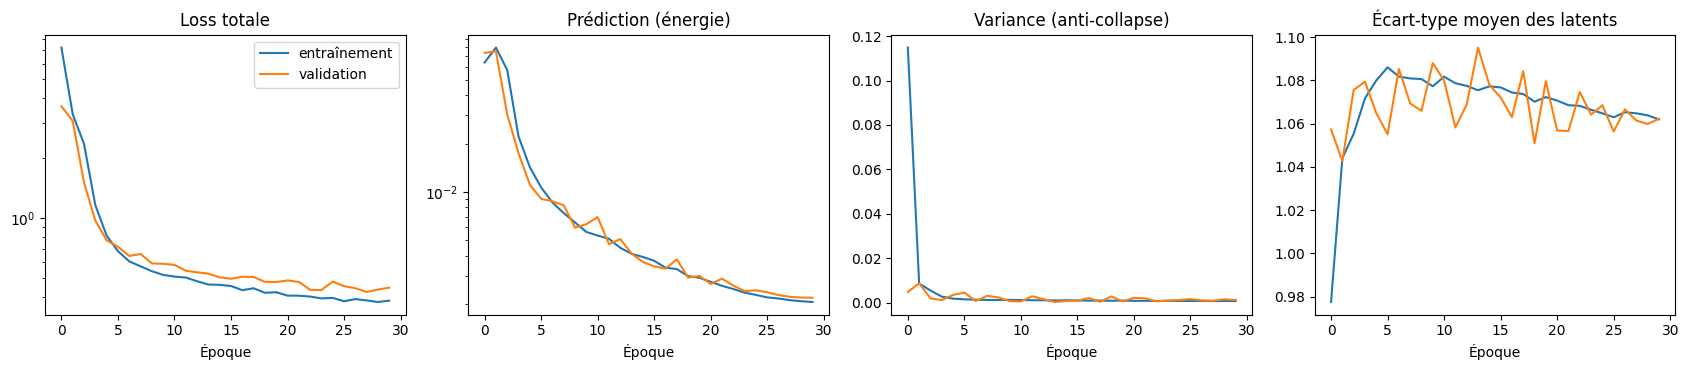

In [23]:
#Courbes d'apprentissage (sauvegardées en PNG)
metrics = ["loss", "pred", "var", "std"]
titles = ["Loss totale", "Prédiction (énergie)", "Variance (anti-collapse)", "Écart-type moyen des latents"]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, key, title in zip(axes, metrics, titles):
    ax.plot([m[key] for m in history["train"]], label="entraînement")
    ax.plot([m[key] for m in history["val"]], label="validation")
    ax.set_title(title); ax.set_xlabel("Époque")
    if key in ("loss", "pred"):
        ax.set_yscale("log")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/jepa_training.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
print(os.path.exists(f"{FIG_DIR}/jepa_training.png"))

True


### Interprétation des courbes d'entraînement de la JEPA

L'encodeur et le prédicteur sont entraînés ensemble pendant 30 époques, avec une loss combinant un
terme de prédiction dans l'espace latent (énergie) et les termes de variance et de covariance de VICReg.

**Pas de collapse.** L'écart-type moyen des latents reste compris entre 1,04 et 1,08 pendant tout
l'entraînement : les latents varient bien d'une observation à l'autre. Il se stabilise juste au-dessus
du seuil de 1 imposé par le terme de variance, sans croître indéfiniment, conformément au rôle de
plancher de ce terme. Sur l'entraînement, le terme de variance tombe presque à zéro dès les
premières époques.

**Le prédicteur apprend la dynamique latente.** L'énergie de prédiction diminue régulièrement,
d'environ 3e-2 à 3e-3, et les courbes d'entraînement et de validation se superposent. Comme les
latents ont un écart-type proche de 1, l'erreur de prédiction finale correspond à environ 5 % de leur
dispersion, et le prédicteur généralise aux trajectoires jamais vues.

**Pas de surapprentissage.** Les courbes de validation suivent celles d'entraînement pour tous les
termes de la loss. Un léger écart subsiste sur la loss totale en fin d'entraînement, alors que les
termes de prédiction et de variance sont superposés.

*Remarque méthodologique.* Lors d'un premier entraînement, le loader de validation n'était pas mélangé :
la loss totale de validation restait alors bien plus élevée que celle d'entraînement (≈ 2,6 contre
≈ 0,4), alors que les termes de prédiction étaient identiques. Les termes de variance et de covariance
de VICReg sont en effet calculés sur chaque batch : un batch de transitions consécutives, issues d'une
ou deux trajectoires, contient des latents peu variés et corrélés, ce qui augmente mécaniquement ces
termes. Mélanger les données de validation a supprimé cet écart. Les statistiques de VICReg doivent
donc toujours être mesurées sur des batchs variés.

**Limite.** Un espace latent qui ne s'effondre pas et une énergie de prédiction faible ne garantissent pas
que le latent contient la position de la balle. Cette vérification sera l'objet de la sonde linéaire.

In [25]:
# Vérification des sauvegardes (lecture seule : on n'écrase RIEN ici)
import os
print("Modèle sur le Drive     :", os.path.exists(MODEL_PATH))
print("Historique sur le Drive :", os.path.exists(HISTORY_PATH))
print("Figures                 :", sorted(os.listdir(FIG_DIR)))


Modèle sur le Drive     : True
Historique sur le Drive : True
Figures                 : ['jepa_training.png', 'latent_rollout_error.png', 'latent_rollouts.png']


JEPA est entraîné. ON sait que l'espace latent ne s'est pas éffondré et que le prédicteur a potentiellement appris à prédire le latent suivant. Ce qu'on ne sait pas c'estt ce que l'espace latent contient. Des vecteurs de 32 nombres difficile voir impossible à interpréter et rien ne dis jusque là que ces nombres capturent la dynamique utile de la balle.

**Alors l'encoder a t-il compris, tout seul, où est la balle sur chaque image et où elle va ?**

## 6- La sonde linéaire

Nous allons ici utilisé une méthode très simple : la regression linéaire pour vérifier que l'encoder capture bien la dynamique de la balle rebondissante.

Si à partir de $s(t)$ la sonde retrouve la position de la balle alors l'encoder l'a bien représenté.

6.a- On va calculer le latent $s(t)$ de chaque observatiion $x(t)$ et récupérer les vraies positions et vitesses.

On passe toutes les images dans l’encodeur pour obtenir leurs latents, et on met en face les vraies positions et vitesses.

In [26]:
@torch.no_grad()
def encode_split(name):
    """Encode toutes les observations d'un split. Renvoie les latents et les vraies position et vitesse."""
    encoder.eval()
    loader = DataLoader(datasets[name], batch_size=512, shuffle=False, num_workers=2)
    latents = torch.cat([encoder(obs.to(device)).cpu() for obs, _, _ in loader]).numpy()

    # Vraies valeurs, dans le même ordre que le dataset
    index = datasets[name].index
    positions = np.array([all_positions[i, t] for i, t in index])
    velocities = np.array([all_positions[i, t] - all_positions[i, t - 1] for i, t in index])
    targets = np.concatenate([positions, velocities], axis=1)   # (N, 4) : x, y, vx, vy
    return latents, targets

S_train, Y_train = encode_split("train")
S_test, Y_test = encode_split("test")
print("Latents :", S_train.shape, "| Cibles :", Y_train.shape)

Latents : (79200, 32) | Cibles : (79200, 4)


6-b- Le rang effectif : combien de dimensions sont vraiment utilisées ?

On calcule les valeurs propres de la matrice de covariance des directions latentes, puis le rang effectif, entre 1 (collapse dimensionnel complet) et 32 (toutes les dimensions pleinement utilisées).

Rang effectif : 32.0 / 32


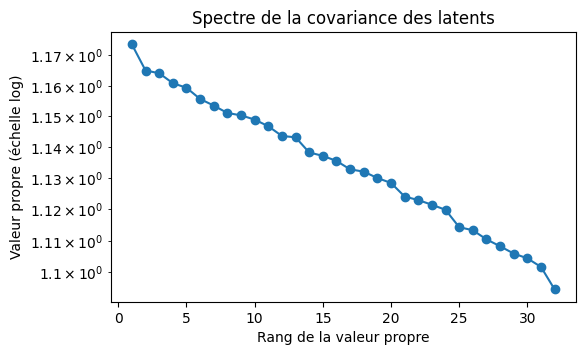

In [27]:
cov = np.cov(S_train, rowvar=False)                 # (32, 32)
eigvals = np.linalg.eigvalsh(cov)[::-1]             # valeurs propres, de la plus grande à la plus petite
p = eigvals / eigvals.sum()
effective_rank = np.exp(-np.sum(p * np.log(p + 1e-12)))
print(f"Rang effectif : {effective_rank:.1f} / {LATENT_DIM}")

plt.figure(figsize=(6, 3.5))
plt.semilogy(np.arange(1, LATENT_DIM + 1), eigvals, "o-")
plt.xlabel("Rang de la valeur propre"); plt.ylabel("Valeur propre (échelle log)")
plt.title("Spectre de la covariance des latents")
plt.show()

**Rang effectif** : 32 / 32. C’est le maximum possible : VICReg a parfaitement rempli son rôle.

Les 32 valeurs propres sont toutes comprises entre 1,09 et 1,17, donc quasiment égales. Le nuage des latents est à peu près une boule dans l’espace à 32 dimensions, et non une aiguille ou une galette dégénérée. Aucune direction n’est négligée : il n’y a aucun collapse dimensionnel.

Attention uand même à la lecture du graphique : l’échelle logarithmique et la plage très resserrée (de 1,09 à 1,17) donnent une impression de forte décroissance. En réalité, l’écart entre la plus grande et la plus petite valeur propre n’est que de 7 %. Un vrai collapse donnerait des valeurs propres s’étalant sur plusieurs ordres de grandeur, par exemple de 10 à 0,0001.

**Une analyse pertinente** :

La balle n’a que 4 degrés de liberté : $x$, $y$, $v_x$, $v_y$. Et pourtant, l’encodeur utilise pleinement ses 32 dimensions. Comment ?

C’est la contrainte de VICReg qui l’y oblige : il doit décorréler ses dimensions. Il les remplit donc avec des fonctions non linéaires différentes des mêmes 4 grandeurs, par exemple $x$, $x^2$, $xy$, ou des motifs plus complexes. Ces fonctions sont décorrélées entre elles, même si elles dépendent toutes des mêmes 4 nombres.

C’est une limite de VICReg : il contrôle les statistiques d’ordre 2, donc les corrélations linéaires, mais pas les dépendances non linéaires. Les 32 dimensions sont bien décorrélées, sans pour autant contenir 32 informations indépendantes puisqu'il n'y en a que 4.

Conséquence pratique : le rang effectif confirme l’absence de collapse, mais il ne dit pas si la position est facilement lisible dans le latent. C’est exactement ce que va trancher la sonde linéaire.

4. La sonde linéaire : le latent contient-il la balle ?

La méthode: on ajuste une régression linéaire $y = S\beta$, des latents vers les vraies position et vitesse, sur l’entraînement, puis on mesure sa qualité sur le test.

Une sonde linéaire est volontairement simple : si elle réussit, c’est que l’information est déjà facilement accessible dans le latent, et non cachée de façon compliquée.

Le contrôle indispensable : on fait la même chose avec un encodeur non entraîné, aux poids aléatoires. Même un encodeur aléatoire conserve une partie de l’information de l’image. La comparaison montrera ce que l’entraînement JEPA a ajouté.

#### Trois objets à ne pas confondre

| Notation | Ce que c’est | Qui le connaît |
| :--- | :--- | :--- |
| $x(t-1), x(t)$ | Les images, l’observation | L’encodeur : c’est son entrée |
| $s(t)$ | Le latent, $32$ nombres | L’encodeur : c’est sa sortie |
| $Y$ | La vraie position et la vraie vitesse : $(x, y, v_x, v_y)$ | Nous seulement, via le simulateur |

La sonde cherche donc à passer du latent aux vraies grandeurs physiques :

$$s(t) \ \longrightarrow \ \big(x,\ y,\ v_x,\ v_y\big)$$

On cherche à savoir si l’information physique est bien encodée dans le l'espace latent.

#### Et oui, c’est bien ça qu’on teste

Existe-t-il un modèle linéaire qui permet de passer de $s(t)$ à ces grandeurs ?
* **Si oui :** l’information est encodée linéairement, donc directement lisible.
* **Si non, mais qu’un MLP y arrive :** l’information est là, mais sous une forme non linéaire.
* **Si aucun des deux n’y arrive :** l’information n’est tout simplement pas encodée dans l'espace latent.

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def probe(S_tr, Y_tr, S_te, Y_te, label):
    """Ajuste une sonde linéaire et affiche le R² et l'erreur de position sur le test."""
    reg = LinearRegression().fit(S_tr, Y_tr)
    Y_pred = reg.predict(S_te)
    r2 = r2_score(Y_te, Y_pred, multioutput="raw_values")
    pos_err = np.linalg.norm(Y_pred[:, :2] - Y_te[:, :2], axis=1).mean()
    print(f"{label:24s} | R² x {r2[0]:.3f}  y {r2[1]:.3f}  vx {r2[2]:.3f}  vy {r2[3]:.3f} "
          f"| erreur de position {pos_err:.4f}")
    return Y_pred

# Encodeur entraîné par la JEPA
Y_pred_jepa = probe(S_train, Y_train, S_test, Y_test, "Encodeur JEPA")

# Contrôle : encodeur aléatoire, non entraîné.
# Il vit dans sa propre variable : encoder n'est jamais modifié.
@torch.no_grad()
def encode_with(enc, name):
    """Encode un split avec un encodeur donné, sans toucher aux variables globales."""
    enc.eval()
    loader = DataLoader(datasets[name], batch_size=512, shuffle=False, num_workers=2)
    return torch.cat([enc(obs.to(device)).cpu() for obs, _, _ in loader]).numpy()

torch.manual_seed(SEED)
random_encoder = Encoder().to(device)
S_train_rand = encode_with(random_encoder, "train")
S_test_rand = encode_with(random_encoder, "test")
probe(S_train_rand, Y_train, S_test_rand, Y_test, "Encodeur aléatoire")


Encodeur JEPA            | R² x 0.953  y 0.987  vx 0.064  vy 0.017 | erreur de position 0.0604
Encodeur aléatoire       | R² x 0.405  y 0.501  vx 0.002  vy 0.004 | erreur de position 0.2596


array([[ 0.35007432,  0.38342246, -0.00237767,  0.00145014],
       [ 0.27474356,  0.20737186, -0.00232681,  0.00152983],
       [ 0.3558804 ,  0.38335046, -0.00151167,  0.0019303 ],
       ...,
       [ 0.55024374,  0.6239011 ,  0.00419838,  0.00192459],
       [ 0.6079612 ,  0.6233958 ,  0.00333646,  0.0018882 ],
       [ 0.5412228 ,  0.6556599 ,  0.00208236,  0.00112304]],
      shape=(9900, 4), dtype=float32)

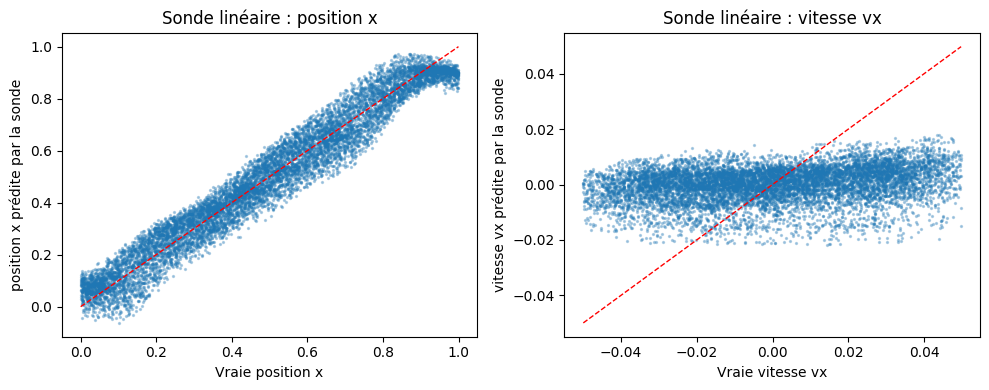

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k, name in [(axes[0], 0, "position x"), (axes[1], 2, "vitesse vx")]:
    ax.scatter(Y_test[:, k], Y_pred_jepa[:, k], s=2, alpha=0.3)
    lims = [Y_test[:, k].min(), Y_test[:, k].max()]
    ax.plot(lims, lims, "r--", lw=1)          # prédiction parfaite
    ax.set_xlabel(f"Vraie {name}"); ax.set_ylabel(f"{name} prédite par la sonde")
    ax.set_title(f"Sonde linéaire : {name}")
plt.tight_layout(); plt.show()

In [30]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(128, 128), max_iter=300, random_state=SEED),
)
mlp.fit(S_train, Y_train)
Y_pred_mlp = mlp.predict(S_test)
r2 = r2_score(Y_test, Y_pred_mlp, multioutput="raw_values")
pos_err = np.linalg.norm(Y_pred_mlp[:, :2] - Y_test[:, :2], axis=1).mean()
print(f"Sonde MLP (JEPA)         | R² x {r2[0]:.3f}  y {r2[1]:.3f}  vx {r2[2]:.3f}  vy {r2[3]:.3f} "
      f"| erreur de position {pos_err:.4f}")

Sonde MLP (JEPA)         | R² x 0.999  y 0.998  vx 0.908  vy 0.902 | erreur de position 0.0128


### Interprétation : que contient le latent ?

Pour savoir ce que l'encodeur a appris, on entraîne des sondes qui tentent de retrouver la vraie
position et la vraie vitesse de la balle à partir du latent. les sondes sont entraînées sur les données d'entrainement et évaluées sur les données test. Ces valeurs ne sont utilisées que pour
l'évaluation : la JEPA n'y a jamais eu accès pendant son entraînement.

| Sonde | R² x | R² y | R² vx | R² vy | Erreur de position |
|---|---|---|---|---|---|
| Linéaire (encodeur aléatoire) | 0,405 | 0,501 | 0,002 | 0,004 | 0,260 |
| Linéaire (encodeur JEPA) | 0,946 | 0,986 | 0,064 | 0,006 | 0,063 |
| MLP (encodeur JEPA) | 0,999 | 0,998 | 0,911 | 0,900 | 0,014 |

**L'encodeur a appris à représenter l'état complet de la balle.** La sonde MLP retrouve la position
avec une erreur de 0,014, soit moins d'un demi-pixel, et la vitesse avec un R² d'environ 0,91. Ces
grandeurs sont donc entièrement contenues dans le latent, alors que l'encodeur n'a jamais reçu que
des images.

**La comparaison avec un encodeur aléatoire** montre que ce résultat vient bien de l'entraînement :
avec des poids aléatoires, la sonde linéaire n'atteint qu'un R² d'environ 0,45 pour la position, et
une erreur quatre fois plus grande.

**La position est linéairement accessible, la vitesse ne l'est pas.** La sonde linéaire retrouve
bien la position (R² ≈ 0,97) mais pas du tout la vitesse (R² ≈ 0,03), alors que la sonde MLP retrouve
les deux. La vitesse est donc encodée de façon non linéaire. C'est cohérent avec l'objectif de la
JEPA : rien n'impose à l'encodeur de réserver une direction du latent à la vitesse, puisque le
prédicteur, lui-même non linéaire, peut l'extraire du latent complet.

**Remarque méthodologique.** Une sonde linéaire qui échoue n'indique pas que l'information est absente,
mais seulement qu'elle n'est pas directement accessible. Les deux sondes sont complémentaires : la
sonde linéaire mesure l'accessibilité de l'information, la sonde non linéaire sa présence.

**Rang effectif.** Les 32 valeurs propres de la covariance des latents sont comprises entre 1,09 et
1,17, soit un rang effectif de 32,0 sur 32 : aucune direction n'est inutilisée. La balle n'ayant que
4 degrés de liberté, l'encodeur remplit les dimensions restantes avec des fonctions non linéaires
décorrélées de ces mêmes grandeurs. VICReg ne contrôle en effet que les corrélations linéaires.

## 7- Qualité des prédictions et rollout.

On sait que le latent contient la position et la vitesse, et que le prédicteur prédit bien le latent suivant sur un pas. Mais chaque prédiction contient une erreur $\epsilon$. Une erreur $\epsilon$ dans l'espace latent vaudrait quoi dans l'espace physique. Aussi pour planifier, le model devra enchaîner plusieurs pas d’imagination. La question qu'on se pose ici est la suivante : jusqu’où ses prédictions restent-elles fiables sachant que l'erreur $\epsilon$ pourrait se propager au fil des prédictions succesives?

In [31]:
for name in ["encoder", "predictor", "mlp", "all_positions", "all_frames", "all_actions"]:
    print(f"{name:15s} : {name in globals()}")

encoder         : True
predictor       : True
mlp             : True
all_positions   : True
all_frames      : True
all_actions     : True


In [32]:
@torch.no_grad()
def rollout_latent(s0, action_seqs):
    """
    Imagine des trajectoires dans l'espace latent.
    s0 : (N, D) latents de départ.c'est le nombre de trajectoires à imaginer.
    action_seqs : (N, H, 2) suites d'actions, normalisées par A_MAX. H c'est le nombre d'action sur une trajectoire.
    Retourne : (N, H, D) latents imaginés.
    """
    predictor.eval()
    s = s0
    out = []
    for h in range(action_seqs.shape[1]):
        s = predictor(s, action_seqs[:, h])
        out.append(s)
    return torch.stack(out, dim=1)

In [33]:
# les rollouts sur les données test ( rollout partant de 200 s0 pris dns les données test)
H = 5          # horizon maximal
N_ROLL = 200    # nombre de rollouts évalués ( nombre de trajectoire latentes)

rng_eval = np.random.default_rng(SEED)
test_ids = split_indices["test"]
starts = [(i, rng_eval.integers(1, N_STEPS - 1 - H)) for i in rng_eval.choice(test_ids, N_ROLL)]

obs0 = np.stack([all_frames[i, t - 1 : t + 1] for i, t in starts]).astype(np.float32) / 255.0
acts = np.stack([all_actions[i, t : t + H] for i, t in starts]) / A_MAX
true_pos = np.stack([all_positions[i, t + 1 : t + 1 + H] for i, t in starts])   # (N_ROLL, H, 2)

encoder.eval()
with torch.no_grad():
    s0 = encoder(torch.tensor(obs0).to(device))
s_imagined = rollout_latent(s0, torch.tensor(acts, dtype=torch.float32).to(device))
print("Latents imaginés :", tuple(s_imagined.shape))

Latents imaginés : (200, 5, 32)


In [34]:
# La sonde MLP lit les latents imaginés
flat = s_imagined.reshape(-1, LATENT_DIM).cpu().numpy()
pos_imagined = mlp.predict(flat)[:, :2].reshape(N_ROLL, H, 2)
err_rollout = np.linalg.norm(pos_imagined - true_pos, axis=-1).mean(axis=0)   # (H,)

# Plancher : erreur de la sonde sur les VRAIS latents (limite de lecture, pas de prédiction)
obs_true = np.stack([all_frames[i, t : t + 2] for i, t in starts]).astype(np.float32) / 255.0
with torch.no_grad():
    s_true = encoder(torch.tensor(obs_true).to(device))
floor = np.linalg.norm(mlp.predict(s_true.cpu().numpy())[:, :2] - true_pos[:, 0], axis=-1).mean()

print(f"Plancher (sonde sur vrais latents) : {floor:.4f}")
for h in range(1 , H+1):
    print(f"Horizon {h:2d} pas | erreur de position {err_rollout[h - 1]:.4f}")

Plancher (sonde sur vrais latents) : 0.0118
Horizon  1 pas | erreur de position 0.0158
Horizon  2 pas | erreur de position 0.0248
Horizon  3 pas | erreur de position 0.0379
Horizon  4 pas | erreur de position 0.0564
Horizon  5 pas | erreur de position 0.0808


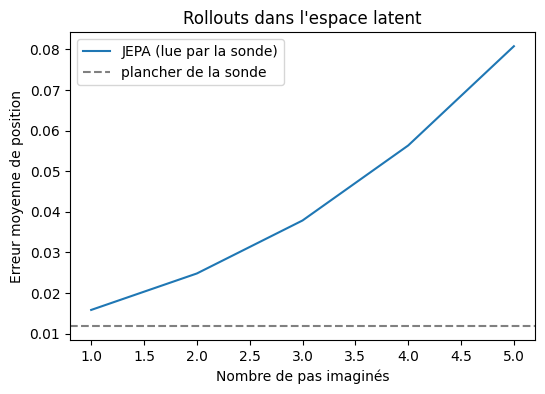

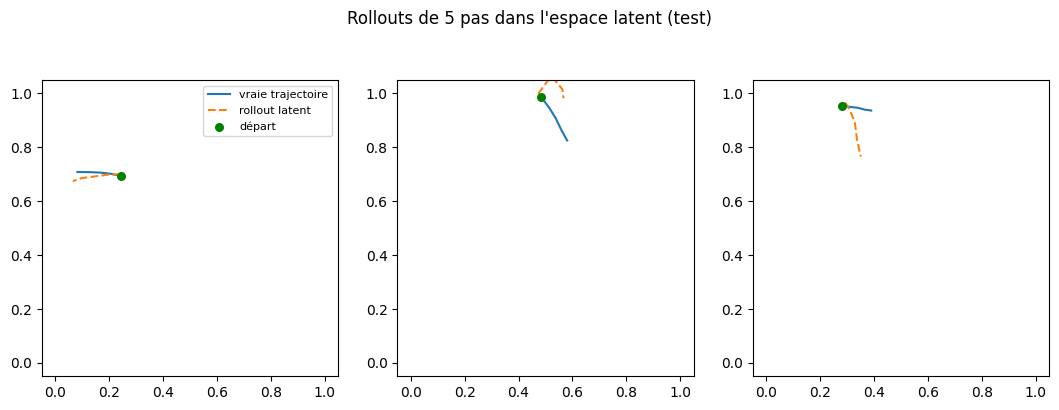

In [36]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, H + 1), err_rollout, label="JEPA (lue par la sonde)")
plt.axhline(floor, color="gray", linestyle="--", label="plancher de la sonde")
plt.xlabel("Nombre de pas imaginés"); plt.ylabel("Erreur moyenne de position")
plt.legend(); plt.title("Rollouts dans l'espace latent")
plt.savefig(f"{FIG_DIR}/latent_rollout_error.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, k in zip(axes, range(3)):
    ax.plot(*true_pos[k].T, label="vraie trajectoire", lw=1.5)
    ax.plot(*pos_imagined[k].T, "--", label="rollout latent", lw=1.5)
    ax.scatter(*true_pos[k, 0], c="green", s=30, zorder=5, label="départ")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect("equal")
axes[0].legend(fontsize=8)
plt.suptitle(f"Rollouts de {H} pas dans l'espace latent (test)")
plt.savefig(f"{FIG_DIR}/latent_rollouts.png", dpi=150, bbox_inches="tight")
plt.show()

**Première version — entraînement à un seul pas.** Le rollout diverge : l'erreur double tous les
deux pas et explose au-delà. Le prédicteur n'a vu que des latents réels en entrée ; dès qu'on lui
réinjecte ses propres prédictions, il sort de son domaine d'entraînement.

**Correction : entraînement multi-pas.** On lui demande d'enchaîner K = 5 prédictions pendant
l'entraînement, chacune comparée au vrai latent du même instant. Il reçoit donc des latents déjà
dérivés et apprend à les ramener vers la bonne trajectoire.

Je n'avais plus de quota GPU sur Colab donc l'entraînement a été fait sur mes 30h/semaine de GPU T4
sur Kaggle et le modèle a été importé sur mon Drive avec l'historique de l'entraînement.

J'ai donc entraîné un nouveau modèle Enc-Pred, mais avec une **loss de prédiction multi-pas**.

**Le problème.** Dans la première version, le prédicteur n'était entraîné que sur un seul pas :
il ne recevait en entrée que des latents produits par l'encodeur à partir de vraies images. En
rollout, on lui réinjecte ses propres prédictions, légèrement décalées : il se retrouve hors de son
domaine d'entraînement, produit une prédiction encore plus décalée, et l'erreur explose de façon
exponentielle.

**La correction.** Pendant l'entraînement, on enchaîne $K = 5$ prédictions à partir d'un seul latent
réel, et on compare *chacune* au vrai latent du même instant :

$$
\mathcal{L}_{\text{pred}} = \frac{1}{K}\sum_{k=1}^{K}
\big\| \hat{s}(t+k) - \mathrm{Enc}\big(x(t+k-1),\, x(t+k)\big) \big\|^2,
\qquad \hat{s}(t+k) = \mathrm{Pred}\big(\hat{s}(t+k-1),\, a(t+k-1)\big)
$$

Le point clé est que $\hat{s}(t+k)$ part du latent **imaginé** et non du latent réel. Le prédicteur
reçoit donc en entrée ses propres latents dérivés, et le gradient le pousse à les ramener vers la
trajectoire correcte. La correction n'est pas ajoutée à la main : elle est apprise.

Les termes de variance et de covariance de VICReg sont appliqués à l'ensemble des $K+1$ latents
réels de la séquence, et non plus à deux seulement.

**Ce que ça change.** Le rapport entre l'erreur au 5ᵉ pas et l'erreur au 1ᵉʳ pas passe de 15 au
début de l'entraînement à environ 4,5 à la fin : la croissance de l'erreur devient quasi linéaire
au lieu d'exploser. L'écart-type des latents reste stable autour de 1,07, donc la modification
n'a pas réintroduit de collapse.

In [39]:
import os, json
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/jepa_world_model"
FIG_DIR = f"{PROJECT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

RUN = "K5"
MODEL_PATH = f"{PROJECT_DIR}/jepa_step3{RUN}.pt"
HISTORY_PATH = f"{PROJECT_DIR}/history{RUN}.json"
print("Fichiers :", MODEL_PATH, "|", HISTORY_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichiers : /content/drive/MyDrive/jepa_world_model/jepa_step3K5.pt | /content/drive/MyDrive/jepa_world_model/historyK5.json


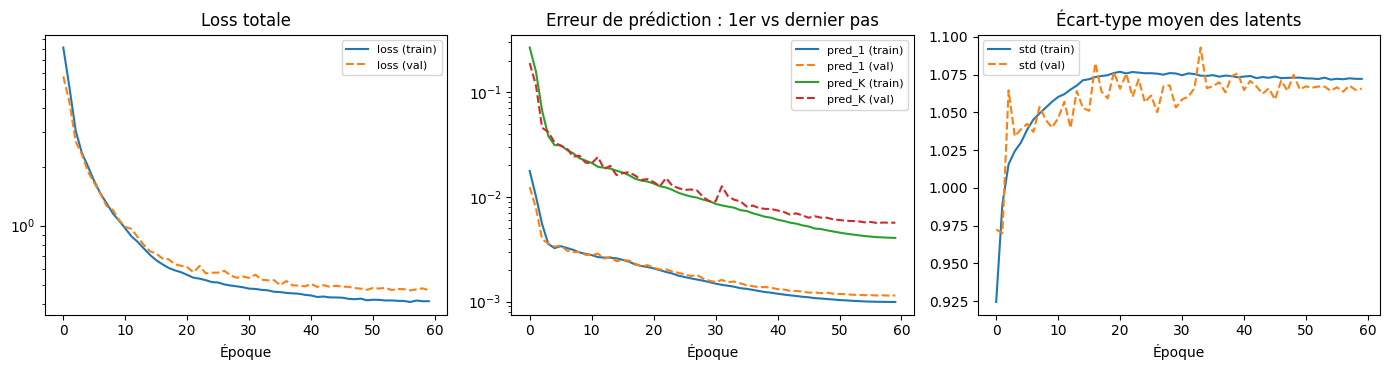

In [40]:
with open(HISTORY_PATH) as f:
    history = json.load(f)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, keys, title in [
    (axes[0], ["loss"], "Loss totale"),
    (axes[1], ["pred_1", "pred_K"], "Erreur de prédiction : 1er vs dernier pas"),
    (axes[2], ["std"], "Écart-type moyen des latents"),
]:
    for key in keys:
        ax.plot([m[key] for m in history["train"]], label=f"{key} (train)")
        ax.plot([m[key] for m in history["val"]], "--", label=f"{key} (val)")
    ax.set_title(title); ax.set_xlabel("Époque"); ax.legend(fontsize=8)
    if "std" not in keys:
        ax.set_yscale("log")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/jepa_training_{RUN}.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation des courbes d'entraînement (K = 5)

**Loss totale.** Elle décroît régulièrement sur 60 époques et s'aplatit à partir de l'époque 40
environ. Les courbes d'entraînement et de validation restent proches, avec un léger écart en fin
d'entraînement.

**Erreur de prédiction : 1er vs dernier pas.** C'est la courbe centrale, et la plus informative.
Les deux niveaux descendent ensemble, mais surtout leur **écart se resserre** : le rapport entre
l'erreur au 5ᵉ pas et celle au 1ᵉʳ pas passe d'environ 15 à l'époque 0 à environ 4,5 à la fin.
Le prédicteur ne devient donc pas seulement plus précis sur un pas : il devient **plus stable
lorsqu'on enchaîne ses propres prédictions**, ce qui était précisément l'objectif de la loss
multi-pas.

À la fin de l'entraînement, l'erreur au dernier pas est légèrement plus élevée en validation qu'en
entraînement (courbe rouge au-dessus de la verte à partir de l'époque 25 environ), alors que
l'erreur au premier pas reste superposée. L'écart reste faible, mais il indique qu'il n'y a plus
grand-chose à gagner en prolongeant l'entraînement.

**Écart-type moyen des latents.** Il monte de 0,92 à environ 1,07 dans les premières époques, puis
reste stable jusqu'à la fin. Passer à une loss multi-pas n'a donc pas réintroduit de collapse :
les latents restent variés, juste au-dessus du seuil imposé par le terme de variance de VICReg.
La courbe de validation est plus bruitée que celle d'entraînement, ce qui est attendu puisqu'elle
est calculée sur huit fois moins de données.

In [41]:
checkpoint = torch.load(MODEL_PATH, map_location=device)
encoder = Encoder().to(device)
predictor = Predictor().to(device)
encoder.load_state_dict(checkpoint["encoder"])
predictor.load_state_dict(checkpoint["predictor"])
encoder.eval(); predictor.eval()
print("Poids rechargés :", MODEL_PATH)

Poids rechargés : /content/drive/MyDrive/jepa_world_model/jepa_step3K5.pt


In [42]:
@torch.no_grad()
def encode_split(name):
    """Encode toutes les observations d'un split. Renvoie les latents et les vraies position et vitesse."""
    encoder.eval()
    loader = DataLoader(datasets[name], batch_size=512, shuffle=False, num_workers=2)
    latents = torch.cat([encoder(obs.to(device)).cpu() for obs, _, _ in loader]).numpy()

    index = datasets[name].index
    positions = np.array([all_positions[i, t] for i, t in index])
    velocities = np.array([all_positions[i, t] - all_positions[i, t - 1] for i, t in index])
    targets = np.concatenate([positions, velocities], axis=1)   # (N, 4) : x, y, vx, vy
    return latents, targets

S_train, Y_train = encode_split("train")
S_test, Y_test = encode_split("test")
print("Latents :", S_train.shape, "| Cibles :", Y_train.shape)

Latents : (79200, 32) | Cibles : (79200, 4)


In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def probe(S_tr, Y_tr, S_te, Y_te, label):
    """Ajuste une sonde linéaire et affiche le R² et l'erreur de position sur le test."""
    reg = LinearRegression().fit(S_tr, Y_tr)
    Y_pred = reg.predict(S_te)
    r2 = r2_score(Y_te, Y_pred, multioutput="raw_values")
    pos_err = np.linalg.norm(Y_pred[:, :2] - Y_te[:, :2], axis=1).mean()
    print(f"{label:24s} | R² x {r2[0]:.3f}  y {r2[1]:.3f}  vx {r2[2]:.3f}  vy {r2[3]:.3f} "
          f"| erreur de position {pos_err:.4f}")
    return Y_pred

Y_pred_jepa = probe(S_train, Y_train, S_test, Y_test, "Encodeur JEPA")

# Contrôle : encodeur aléatoire, dans sa propre variable
@torch.no_grad()
def encode_with(enc, name):
    enc.eval()
    loader = DataLoader(datasets[name], batch_size=512, shuffle=False, num_workers=2)
    return torch.cat([enc(obs.to(device)).cpu() for obs, _, _ in loader]).numpy()

torch.manual_seed(SEED)
random_encoder = Encoder().to(device)
S_train_rand = encode_with(random_encoder, "train")
S_test_rand = encode_with(random_encoder, "test")
probe(S_train_rand, Y_train, S_test_rand, Y_test, "Encodeur aléatoire")

Encodeur JEPA            | R² x 0.979  y 0.986  vx 0.717  vy 0.892 | erreur de position 0.0450
Encodeur aléatoire       | R² x 0.405  y 0.501  vx 0.002  vy 0.004 | erreur de position 0.2596


array([[ 0.35007432,  0.38342246, -0.00237767,  0.00145014],
       [ 0.27474356,  0.20737186, -0.00232681,  0.00152983],
       [ 0.3558804 ,  0.38335046, -0.00151167,  0.0019303 ],
       ...,
       [ 0.55024374,  0.6239011 ,  0.00419838,  0.00192459],
       [ 0.6079612 ,  0.6233958 ,  0.00333646,  0.0018882 ],
       [ 0.5412228 ,  0.6556599 ,  0.00208236,  0.00112304]],
      shape=(9900, 4), dtype=float32)

In [44]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(128, 128), max_iter=300, random_state=SEED),
)
mlp.fit(S_train, Y_train)
Y_pred_mlp = mlp.predict(S_test)
r2 = r2_score(Y_test, Y_pred_mlp, multioutput="raw_values")
pos_err = np.linalg.norm(Y_pred_mlp[:, :2] - Y_test[:, :2], axis=1).mean()
print(f"Sonde MLP (JEPA)         | R² x {r2[0]:.3f}  y {r2[1]:.3f}  vx {r2[2]:.3f}  vy {r2[3]:.3f} "
      f"| erreur de position {pos_err:.4f}")

Sonde MLP (JEPA)         | R² x 0.998  y 0.999  vx 0.901  vy 0.917 | erreur de position 0.0143


In [45]:
@torch.no_grad()
def rollout_latent(s0, action_seqs):
    """
    Imagine des trajectoires dans l'espace latent.
    s0 : (N, D) latents de départ.
    action_seqs : (N, H, 2) suites d'actions, normalisées par A_MAX.
    Retourne : (N, H, D) latents imaginés.
    """
    predictor.eval()
    s = s0
    out = []
    for h in range(action_seqs.shape[1]):
        s = predictor(s, action_seqs[:, h])
        out.append(s)
    return torch.stack(out, dim=1)

In [46]:
H = 20          # au-delà des 5 pas vus à l'entraînement
N_ROLL = 200

rng_eval = np.random.default_rng(SEED)
test_ids = split_indices["test"]
starts = [(i, rng_eval.integers(1, N_STEPS - 1 - H)) for i in rng_eval.choice(test_ids, N_ROLL)]

obs0 = np.stack([all_frames[i, t - 1 : t + 1] for i, t in starts]).astype(np.float32) / 255.0
acts = np.stack([all_actions[i, t : t + H] for i, t in starts]) / A_MAX
true_pos = np.stack([all_positions[i, t + 1 : t + 1 + H] for i, t in starts])

with torch.no_grad():
    s0 = encoder(torch.tensor(obs0).to(device))
s_imagined = rollout_latent(s0, torch.tensor(acts, dtype=torch.float32).to(device))

flat = s_imagined.reshape(-1, LATENT_DIM).cpu().numpy()
pos_imagined = mlp.predict(flat)[:, :2].reshape(N_ROLL, H, 2)
err_rollout = np.linalg.norm(pos_imagined - true_pos, axis=-1).mean(axis=0)

obs_true = np.stack([all_frames[i, t : t + 2] for i, t in starts]).astype(np.float32) / 255.0
with torch.no_grad():
    s_true = encoder(torch.tensor(obs_true).to(device))
floor = np.linalg.norm(mlp.predict(s_true.cpu().numpy())[:, :2] - true_pos[:, 0], axis=-1).mean()

print(f"Plancher (sonde sur vrais latents) : {floor:.4f}")
for h in [1, 2, 3, 5, 10, 15, 20]:
    print(f"Horizon {h:2d} pas | erreur de position {err_rollout[h - 1]:.4f}")

Plancher (sonde sur vrais latents) : 0.0135
Horizon  1 pas | erreur de position 0.0137
Horizon  2 pas | erreur de position 0.0155
Horizon  3 pas | erreur de position 0.0174
Horizon  5 pas | erreur de position 0.0220
Horizon 10 pas | erreur de position 0.0364
Horizon 15 pas | erreur de position 0.0555
Horizon 20 pas | erreur de position 0.0793


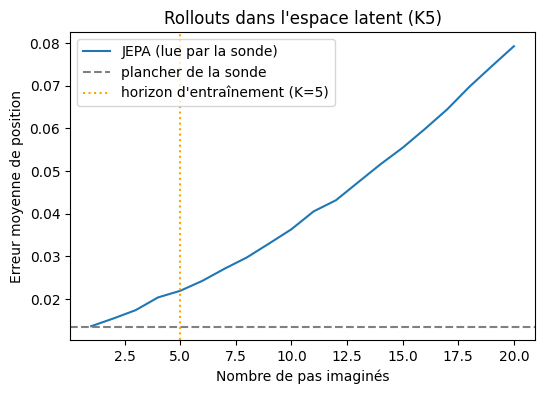

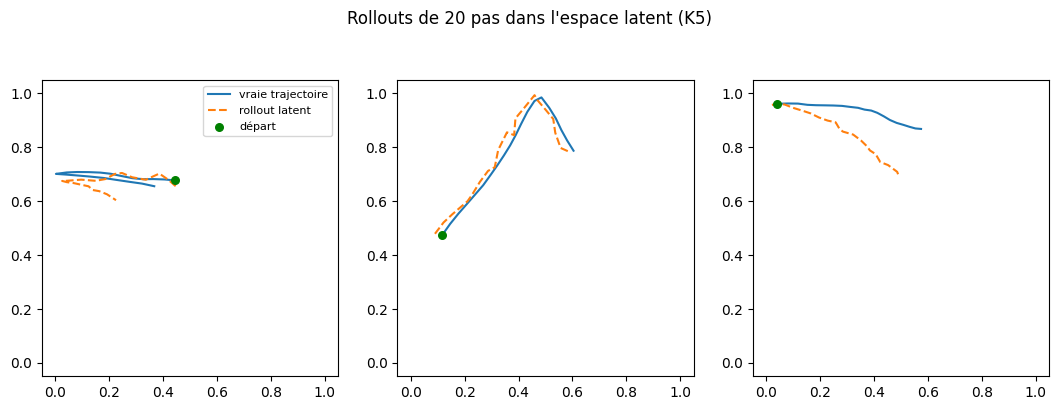

In [47]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, H + 1), err_rollout, label="JEPA (lue par la sonde)")
plt.axhline(floor, color="gray", linestyle="--", label="plancher de la sonde")
plt.axvline(5, color="orange", linestyle=":", label="horizon d'entraînement (K=5)")
plt.xlabel("Nombre de pas imaginés"); plt.ylabel("Erreur moyenne de position")
plt.legend(); plt.title(f"Rollouts dans l'espace latent ({RUN})")
plt.savefig(f"{FIG_DIR}/latent_rollout_error_{RUN}.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, k in zip(axes, range(3)):
    ax.plot(*true_pos[k].T, label="vraie trajectoire", lw=1.5)
    ax.plot(*pos_imagined[k].T, "--", label="rollout latent", lw=1.5)
    ax.scatter(*true_pos[k, 0], c="green", s=30, zorder=5, label="départ")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect("equal")
axes[0].legend(fontsize=8)
plt.suptitle(f"Rollouts de {H} pas dans l'espace latent ({RUN})")
plt.savefig(f"{FIG_DIR}/latent_rollouts_{RUN}.png", dpi=150, bbox_inches="tight")
plt.show()

### Rollouts dans l'espace latent (K = 5)

Le modèle part d'une vraie observation, l'encode, puis enchaîne ses propres prédictions sans jamais
revoir d'image. Chaque latent imaginé est traduit en position par la sonde MLP, puis comparé à la
vraie position. L'horizon va jusqu'à 20 pas, soit quatre fois l'horizon vu pendant l'entraînement.

| Horizon | K = 1 | K = 5 |
|---|---|---|
| 1 pas | 0,0157 | **0,0137** |
| 2 pas | 0,0248 | **0,0155** |
| 5 pas | 0,0847 | **0,0220** |
| 20 pas | 4,17 | **0,0793** |

*(plancher de la sonde : 0,0135)*

**L'entraînement multi-pas supprime la divergence.** Avec un entraînement à un seul pas, l'erreur
doublait tous les deux pas et atteignait 4,17 à l'horizon 20, soit plusieurs fois la taille de la
boîte : la balle imaginée en était sortie depuis longtemps. Avec K = 5, l'erreur à ce même horizon
est de 0,079, soit environ 50 fois plus faible, et sa croissance est quasi linéaire (environ 0,0038
par pas entre le 5ᵉ et le 20ᵉ).

**À un pas, la prédiction est gratuite.** L'erreur du rollout (0,0137) est confondue avec le plancher
de la sonde (0,0135) : on ne mesure plus que l'imprécision de lecture, l'erreur du prédicteur est
négligeable devant elle.

**La stabilité se prolonge au-delà de l'horizon d'entraînement.** La courbe ne présente aucune
rupture à K = 5 (ligne orange). Le prédicteur n'a donc pas simplement mémorisé des séquences de
cinq pas : il a appris une dynamique latente stable, qui reste valable quatre fois plus loin.

**Sur les trajectoires**, le rollout suit la vraie trajectoire avec une dérive progressive, sans
partir dans une direction absurde. Il reproduit la forme générale du mouvement, y compris les
changements de direction, et l'écart se creuse lentement avec l'horizon.

**Conséquence pour la planification.** Avec un horizon de 10 pas, l'erreur attendue est d'environ
0,036, soit moins de 4 % de la taille de la boîte. Le modèle est donc suffisamment fiable pour
être utilisé dans un planificateur MPC.

## 8 & 9 - Planification à partir d'une image de la cible et comparaison d'agents.

### L'objectif
C'est l'aboutissement du projet : un agent qui atteint un but sans jamais connaître de coordonnées.
Il ne reçoit que des images, et le but lui-même lui est donné sous forme d'image.

### Le protocole
1. On place une cible dans la boîte et on génère l'image d'une balle posée à cet endroit.C’est une image du but : à quoi ressemblera le monde quand la tâche sera réussie.
2. L'agent l'encode une fois pour toutes : $s_{\text{cible}} = \mathrm{Enc}(x_{\text{cible}})$.
3. À chaque pas, il observe les deux dernières images réelles et les encode : $s(t)$.
4. Il tire au hasard 500 suites de $H$ actions et imagine leurs conséquences dans l'espace latent,
   avec le prédicteur seul :
   $$\hat{s}(t+k) = \mathrm{Pred}\big(\hat{s}(t+k-1),\, a(t+k-1)\big)$$
5. Le coût d'une suite est la distance moyenne, dans le latent, à l'objectif :
   $$C(a_{t:t+H}) = \frac{1}{H}\sum_{k=1}^{H} \big\|\hat{s}(t+k) - s_{\text{cible}}\big\|$$
6. Il exécute la première action de la suite de coût minimal, observe la nouvelle image réelle,
   et recommence (schéma MPC).

Aucune position n'intervient : ni dans l'observation, ni dans le coût, ni dans le choix de l'action.
Les coordonnées ne servent qu'à nous, pour mesurer après coup si la cible a été atteinte.

### Lien avec LeCun (2022)
Tous les modules de l'agent autonome sont maintenant présents et appris ou définis dans l'espace
latent :

| Module | Ici |
|---|---|
| **Perception** | l'encodeur convolutif de la JEPA |
| **World model** | le prédicteur latent, entraîné sur K = 5 pas |
| **Coût** | la distance latente à l'image objectif |
| **Acteur** | le random shooting sur les actions |

C'est la différence essentielle avec l'étape 2, où la perception était fournie à la main et le coût
calculé sur de vraies coordonnées.

### Les agents comparés
Les trois agents jouent exactement les mêmes épisodes.

| Agent | Ce qu'il observe | Rôle |
|---|---|---|
| Aléatoire | rien | borne inf |
| **JEPA** | des images uniquement | agent évalué |
| Oracle | la vraie position et la vraie vitesse | borne sup |

### Critère de réussite
Un épisode est réussi si la balle passe à moins de 0,05 de la cible en au plus 100 pas. On mesure le
taux de réussite et le nombre de pas nécessaires.

L'agent JEPA doit faire nettement mieux que l'agent aléatoire. L'écart avec l'oracle mesure ce que
coûte le fait de ne percevoir le monde qu'à travers des images.

### Le risque spécifique à cette étape
Le latent peut contenir toute l'information utile, par ailleurs la sonde le confirme mais sans pour autant que la
distance entre latents reflète la distance réelle entre positions. Si c'est le cas, le coût
guidera mal l'agent et la planification échouera malgré un bon modèle. C'est une difficulté propre
à la planification en espace latent, et un résultat intéressant en soi si elle se manifeste.

In [49]:
N_SEQ = 500      # nombre de suites d'actions imaginées à chaque pas
HORIZON = 10     # longueur de chaque suite
MAX_STEPS = 100
EPS = 0.05

@torch.no_grad()
def imagine_jepa(s0, action_seqs):
    """
    Imagine N trajectoires dans le latent, à partir d'un même latent de départ.
    s0 : (D,) latent courant.  action_seqs : (N, H, 2) actions normalisées.
    Retourne : (N, H, D) latents imaginés.
    """
    N, H, _ = action_seqs.shape
    s = s0.unsqueeze(0).repeat(N, 1)                       # (N, D) : même départ pour tous
    out = []
    for h in range(H):
        s = predictor(s, action_seqs[:, h])
        out.append(s)
    return torch.stack(out, dim=1)

def imagine_simulator(pos, vel, action_seqs):
    """Oracle : imagine N trajectoires avec la vraie physique. action_seqs en vraies unités."""
    N, H, _ = action_seqs.shape
    p, v = np.repeat(pos[None], N, 0), np.repeat(vel[None], N, 0)
    traj = np.zeros((N, H, 2))
    for h in range(H):
        p, v = env_step(p, v, action_seqs[:, h])
        traj[:, h] = p
    return traj

In [50]:
def agent_random(obs, pos, vel, s_goal, target, rng):
    """Borne basse : poussée au hasard."""
    return rng.uniform(-A_MAX, A_MAX, size=2)

def agent_jepa(obs, pos, vel, s_goal, target, rng):
    """Planifie dans le latent. Ne voit que les images et le latent objectif."""
    seqs = rng.uniform(-1.0, 1.0, size=(N_SEQ, HORIZON, 2))          # actions normalisées
    seqs_t = torch.tensor(seqs, dtype=torch.float32, device=device)
    with torch.no_grad():
        s0 = encoder(torch.tensor(obs[None], dtype=torch.float32, device=device))[0]
        traj = imagine_jepa(s0, seqs_t)                               # (N, H, D)
        cost = (traj - s_goal).norm(dim=-1).mean(dim=1)               # distance LATENTE
    best = cost.argmin().item()
    return seqs[best, 0] * A_MAX                                      # retour en vraies unités

def agent_oracle(obs, pos, vel, s_goal, target, rng):
    """Borne haute : planifie avec la vraie physique et les vraies coordonnées."""
    seqs = rng.uniform(-A_MAX, A_MAX, size=(N_SEQ, HORIZON, 2))
    traj = imagine_simulator(pos, vel, seqs)
    cost = np.linalg.norm(traj - target, axis=-1).mean(axis=1)        # distance en POSITION
    return seqs[cost.argmin(), 0]

In [57]:
def make_episodes(n, rng):
    """Tire n situations : position et vitesse de départ, et cible."""
    eps = []
    for _ in range(n):
        pos = rng.uniform(0.1, 0.9, size=2)
        angle = rng.uniform(0.0, 2.0 * np.pi)
        vel = V_INIT * np.array([np.cos(angle), np.sin(angle)])
        target = rng.uniform(0.1, 0.9, size=2)
        eps.append((pos, vel, target))
    return eps

@torch.no_grad()
def encode_goal(target):
    """Image de la balle posée sur la cible, dupliquée pour former une observation (balle immobile)."""
    img = render(target)                                              # (32, 32)
    obs = np.stack([img, img])                                        # (2, 32, 32)
    return encoder(torch.tensor(obs[None], dtype=torch.float32, device=device))[0]

def run_episode(agent, start, rng):
    """Joue un épisode. Renvoie (succès, nombre de pas, positions parcourues, cible)."""
    pos, vel, target = start
    s_goal = encode_goal(target)

    prev_pos = pos.copy()
    pos, vel = env_step(pos, vel, np.zeros(2))                        # un pas pour avoir 2 images
    history = [prev_pos, pos.copy()]

    for t in range(MAX_STEPS):
        if np.linalg.norm(pos - target) < EPS:
            return True, t, np.array(history), target
        obs = render(np.array(history[-2:]))                          # (2, 32, 32)
        action = agent(obs, pos, vel, s_goal, target, rng)
        pos, vel = env_step(pos, vel, action)
        history.append(pos.copy())

    return np.linalg.norm(pos - target) < EPS, MAX_STEPS, np.array(history), target

In [52]:
N_EPISODES = 50
episodes = make_episodes(N_EPISODES, np.random.default_rng(123))

agents = {
    "Aléatoire": agent_random,
    "JEPA (images seules)": agent_jepa,
    "Oracle (vraie physique)": agent_oracle,
}

results = {}
for name, agent in agents.items():
    plan_rng = np.random.default_rng(SEED)
    outcomes = [run_episode(agent, ep, plan_rng) for ep in episodes]
    results[name] = outcomes
    succ = np.array([o[0] for o in outcomes])
    steps = np.array([o[1] for o in outcomes])
    mean_steps = steps[succ].mean() if succ.any() else float("nan")
    print(f"{name:26s} | réussite {succ.mean():6.1%} | pas moyens (si réussite) {mean_steps:5.1f}")

Aléatoire                  | réussite  28.0% | pas moyens (si réussite)  48.9
JEPA (images seules)       | réussite  38.0% | pas moyens (si réussite)  13.4
Oracle (vraie physique)    | réussite 100.0% | pas moyens (si réussite)  17.0


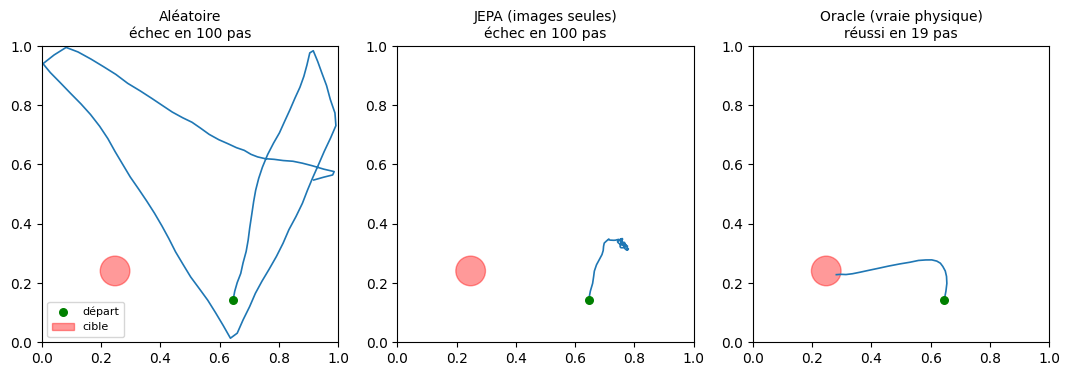

In [53]:
ep_id = 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (name, outcomes) in zip(axes, results.items()):
    success, steps, history, target = outcomes[ep_id]
    ax.plot(*history.T, lw=1.2)
    ax.scatter(*history[0], c="green", s=30, zorder=5, label="départ")
    ax.add_patch(plt.Circle(target, EPS, color="red", alpha=0.4, label="cible"))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_title(f"{name}\n{'réussi' if success else 'échec'} en {steps} pas", fontsize=10)
axes[0].legend(fontsize=8)
plt.savefig(f"{FIG_DIR}/planning_{RUN}.png", dpi=150, bbox_inches="tight")
plt.show()

### Planification à partir d'une image de la cible : premiers résultats

| Agent | Taux de réussite | Pas moyens (si réussite) |
|---|---|---|
| Aléatoire | 28,0 % | 48,9 |
| JEPA (images seules) | 38,0 % | 13,4 |
| Oracle (vraie physique) | 100,0 % | 17,0 |

**L'agent JEPA échoue dans la majorité des épisodes**, alors que le même planificateur atteint 100 %
avec la vraie physique. Le world model n'est donc pas en cause seul : les rollouts ont montré qu'il
prédit correctement sur 20 pas.

Deux éléments orientent le diagnostic :
- **Quand il réussit, il est rapide** : 13,4 pas, moins que l'oracle. Il ne réussit donc que les
  cibles déjà proches. C'est cohérent avec le fait qu'il est entraîné sur K=5
- **Sur les trajectoires**, il part dans la bonne direction puis s'immobilise à mi-chemin et oscille
  sur place, comme s'il avait atteint son but. Comme si on avait atteint un minimum local du coût latent.

Corrélation : 0.36974547992298773


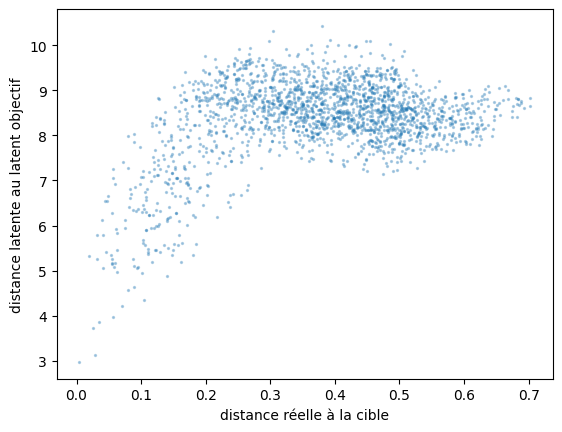

In [58]:
# Corrélation entre distance latente et distance réelle
idx = np.random.default_rng(0).choice(len(S_test), 2000, replace=False)
S = torch.tensor(S_test[idx], device=device)
P = Y_test[idx, :2]

target = np.array([0.5, 0.5])
s_goal = encode_goal(target)

d_latent = (S - s_goal).norm(dim=-1).cpu().numpy()
d_real = np.linalg.norm(P - target, axis=1)

print("Corrélation :", np.corrcoef(d_latent, d_real)[0, 1])
plt.scatter(d_real, d_latent, s=2, alpha=0.3)
plt.xlabel("distance réelle à la cible"); plt.ylabel("distance latente au latent objectif")
plt.show()

Comme on peut le voir, au delà d'un certain seuil ( environ 0.27 ) la distance latente au latent objectif ne varie pas alors même que la distance réelle à la cible évolue encore.

### Diagnostic : la métrique latente

Le coût de planification est la distance euclidienne entre le latent imaginé et le latent objectif.
Pour qu'il guide l'agent, il faut que cette distance latente croisse ( forte corrélation ++ ) avec la distance réelle à la cible.

**Le problème est la géométrie de l'espace latent.** Rien dans l'objectif de la JEPA n'impose que les
distances latentes reflètent les distances réelles : la loss demande seulement que le latent soit
prédictible, varié et décorrélé. Le latent contient la position, les sondes le montrent mais la
distance euclidienne entre deux latents n'est visiblement pas une mesure fidèle au-delà d'un voisinage.

C'est une difficulté manifeste de la planification en espace latent appris : un bon modèle du monde ne suffit pas, encore faut-il que l'espace où l'on planifie soit
muni d'une métrique exploitable.